# Simple SPH with gravity

In this example, we want to perform the simplest SPH operation: calculate the density field based on the underlying particle distribution. We assume:

- Constant smoothing length.
- Particles interact via short-range gravity, i.e., we neglect long-range contributions. This is because the interaction is calculated based on the local and active sets -- see docs.

We also calculate pressure using the EoS.

In [19]:
import os

import peano4
import peano4.dastgen2
import peano4.toolbox
import peano4.toolbox.particles
import dastgen2

In [20]:
# If we want to start a project from scratch, we may want to remove some of the generated code
!make clean; rm -r actions/ vertexdata/ repositories/ globaldata/ celldata/ observers/ 

project = peano4.Project( ["examples", "particles"], "sph-simple-multiscale-particle-interaction", "." )

rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertRandomParticlesIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/CalcDensities.o ./observers/CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleAMR3.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/CalcDensities.o ./actions/Move.o ./observers/Move2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/Move2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/Move2peano4_t

## Prepare code

Peano's API does not know which settings to use on the present system. To make it copy/clone the settings identified by ./configure, we ask it to parse the generated configuration scripts. 

In [21]:
#build_mode = peano4.output.CompileMode.Asserts
build_mode = peano4.output.CompileMode.Release
project.output.makefile.parse_configure_script_outcome( "../../.." )
project.output.makefile.set_mode( build_mode )

parse configure outcome ../../../config.log to extract configure settings
found the configure call info   $ ./configure --with-mpi=mpicxx --with-multithreading=omp CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops CC=gcc CXX=g++ FC=gfortran --enable-loadbalancing --enable-exahype --enable-particles --enable-blockstructured

parse configure outcome ../../../src/Makefile to extract compile settings
add CXX=mpicxx
add CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops
add CXXFLAGS_PEANO_2D_ASSERTS=-DDimensions=2 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_2D_DEBUG=-DDimensions=2 -DPeanoDebug=4 -g3 -O0
add CXXFLAGS_PEANO_2D_RELEASE=-DDimensions=2 -DPeanoDebug=0
add CXXFLAGS_PEANO_2D_STATS=-DDimensions=2 -DPeanoDebug=0 -DTrackStatistics
add CXXFLAGS_PEANO_2D_TRACE=-DDimensions=2 -DPeanoDebug=1 -g3
add CXXFLAGS_PEANO_3D_ASSERTS=-DDimensions=3 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_3D_DEBUG=-DDimensions=3 -DPeanoDebug=4 -g3

## Model the particle

We create the particle through the toolbox. A particle by definition has a position, so we just need to add everything else for SPH:
- Velocity array
- Acceleration array
- Mass
- Density
- Pressure
- Internal Energy (U)
- Time derivative of internal energy (U')
- Kernel smoothing length

We add a marker to indicate the next calculation step required for a particle so we don't perform the same step on a particle twice in a row.

We also add an array to store the the new position of a particle after a timestep is completed. We will use this to move the particle at the start of the subsequent timestep.

In [22]:
particle = peano4.toolbox.particles.Particle("Particle")

# Define properties
v_attr = peano4.dastgen2.Peano4DoubleArray("v","Dimensions")
a_attr = peano4.dastgen2.Peano4DoubleArray("a","Dimensions")
mass_attr    = dastgen2.attributes.Double("mass")
density_attr = dastgen2.attributes.Double("density")
pressure_attr= dastgen2.attributes.Double("pressure")
u_attr       = dastgen2.attributes.Double("u")
#uDash_attr   = dastgen2.attributes.Double("uDash")
smoothL_attr = dastgen2.attributes.Double("smoothingLength")
#step_attr    = dastgen2.attributes.Enumeration("step", ["calcDensity", "Move"]) # Check!

# Add particle properties
particle.data.add_attribute(v_attr)
particle.data.add_attribute(a_attr)
particle.data.add_attribute(mass_attr)
particle.data.add_attribute(density_attr)
particle.data.add_attribute(pressure_attr)
particle.data.add_attribute(u_attr)
#particle.data.add_attribute(uDash_attr)
particle.data.add_attribute(smoothL_attr)
#particle.data.add_attribute(step_attr)

particles = peano4.toolbox.particles.ParticleSet(particle)

This particle has to be added to the project. This way the project knows that we are working with this guy. We associate the particle with the vertices, as we work with the pidt (particle in dual tree) algorithm. 

In [23]:
project.datamodel.add_global_object(particle)
project.datamodel.add_vertex       (particles)

## Export global SPH constants

There are plenty of constant simulation paramaters to specify for our SPH simulation - we do that here. 

In [24]:
dimensions = 2
project.output.makefile.set_dimension(dimensions)

In [25]:
from numpy import pi

# SPH constants
GAMMA = str(5/3)
DYNAMIC_VISCOSITY     = "0.00001"
CUBIC_SPLINE_SIGMA_2D = str(10/(7*pi))
CUBIC_SPLINE_SIGMA_3D = str(1/pi)
#TARGET_PARTICLE_SIZE  = "0.01"
#ENERGY_SPIKE = "0.1"
#SPIKE_RADIUS = "0.08"
#REST_DENSITY = "1"
#INITIAL_H = "0.02"

project.constants.export_const_with_type("GAMMA", GAMMA, "double")
project.constants.export_const_with_type("DYNAMIC_VISCOSITY", DYNAMIC_VISCOSITY, "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA_2D", CUBIC_SPLINE_SIGMA_2D, "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA_3D", CUBIC_SPLINE_SIGMA_3D, "double")
#project.constants.export_const_with_type("TARGET_PARTICLE_SIZE", TARGET_PARTICLE_SIZE, "double")
#project.constants.export_const_with_type("ENERGY_SPIKE", ENERGY_SPIKE, "double")
#project.constants.export_const_with_type("SPIKE_RADIUS", SPIKE_RADIUS, "double")
#project.constants.export_const_with_type("REST_DENSITY", REST_DENSITY, "double")
#project.constants.export_const_with_type("INITIAL_H", INITIAL_H, "double")

#if dimensions==2:
#  DOMAIN_OFFSET = "{0.0, 0.0}"
#  DOMAIN_SIZE = "{1.0, 1.0}"
#  EXPLOSION_CENTRE = "{0.5, 0.5}"
#else:
#  DOMAIN_OFFSET = "{0.0, 0.0, 0.0}"
#  DOMAIN_SIZE = "{1.0, 1.0, 1.0}"
#  EXPLOSION_CENTRE = "{0.5, 0.5, 0.5}"

#project.constants.export_const_with_type("DOMAIN_OFFSET", DOMAIN_OFFSET, "auto")
#project.constants.export_const_with_type("DOMAIN_SIZE", DOMAIN_SIZE, "auto")
#project.constants.export_const_with_type("EXPLOSION_CENTRE", EXPLOSION_CENTRE, "auto")

## Model the setup phases

The setup remains almost unchanged. I give all particles a biased random initial velocity. This will introduce an adaptive mesh, as particles will cluster in the bottom left part of the 2d domain.

In [26]:
mesh_size = 0.2

particle_tree_analysis = peano4.toolbox.particles.ParticleTreeAnalysis(particles)
project.datamodel.add_cell(particle_tree_analysis.cell_marker)   # read docu of ParticleTreeAnalysis

create_grid = peano4.solversteps.Step( name="CreateGrid", add_user_defined_actions=False )
create_grid.add_action_set( peano4.toolbox.CreateRegularGrid(mesh_size) )
create_grid.use_vertex(particles)
create_grid.use_cell(particle_tree_analysis.cell_marker)
project.solversteps.add_step(create_grid)

## Initial conditions for particles

In [27]:
initialisation_snippet = """
 
 particle->setCutOffRadius(0.05);

 // We will set random velocities for (v_x, v_y)
 particle->setV( 0, 1E0*(0.5 -((double) rand() / (RAND_MAX))) );
 particle->setV( 1, 1E0*(0.5 -((double) rand() / (RAND_MAX))) );
 
 //particle->setV( 0, 0.0);
 //particle->setV( 1, 0.0);
 
 // For SPH, we also want to initialise a few more variables:
 particle->setDensity (1.0);        
 particle->setU       (1.E-2);
 particle->setPressure(1.0);
 particle->setMass    (1E0);        
 particle->setSmoothingLength(0.05);

"""

init_setup = peano4.solversteps.Step( name="Init", add_user_defined_actions=False )
init_setup.use_vertex(particles)
init_setup.use_cell(particle_tree_analysis.cell_marker)
init_setup.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
init_setup.add_action_set( peano4.toolbox.particles.InsertRandomParticlesIntoUnrefinedCells(
  particle_set=particles,
  average_distance_between_particles=mesh_size/10,
  initialisation_call=initialisation_snippet,
  noise=True ))
init_setup.add_action_set( particle_tree_analysis )
project.solversteps.add_step(init_setup)

## Particle behaviour

We stick to exactly the same particle behaviour from a code point of view. However, we use a pre-manufactured toolbox  into which we inject the actual code. The important fact here is that we now do not simply rely on the particles of the adjacent vertices of a cell. Instead, we work with active and local particle sets.

ls: cannot access '../../python/peano4/toolbox/particles': No such file or directory


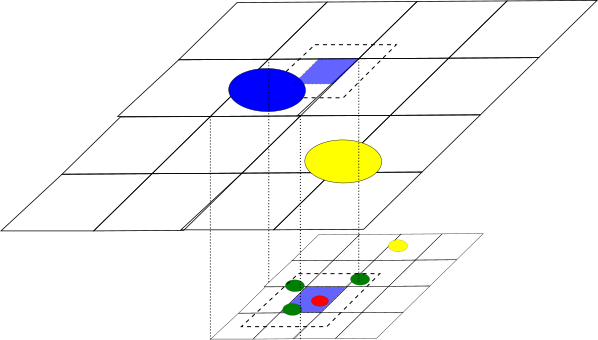

In [28]:
from IPython.display import Image
!ls ../../python/peano4/toolbox/particles
Image("../../../python/peano4/toolbox/particles/dependency_sets.png")

To understand what the individual particles in the sketch above are supposed to mean and how they are maintained and exposed to the user, please consult the documentation of the ParticleParticleInteraction class in the Python toolbox directory. It contains a lot explanations.

## Write the actual particle movement (the move step below)

We will implement the actual particle movement ourselves. For this, we have asked Move to be an action set with manual user code, and indeed we get a Move class in the actions subdirectory once we have triggered the build process. This is, same as main, an empty blueprint. We can alter it, and Peano won't overwrite it anymore after that. If we delete it, the API will regenerate it however. The current example has already a pre-prepared Move, so it won't be empty, but you might want to delete it and regenerate it to see what you get in the first place.

Here's what I changed in the Move class: Move is a standard class which defines an action set: There's a fixed number of callbacks that are invoked by Peano, and we can use these to inject behaviour. I only alter (or plug into) three actions: 

### First access to vertex

Particles are associated to vertices. So when I hit a vertex the first time, I also hit the particles associated with it for the first time. I run over them, and set their status to NotMovedYet:

     for (auto& p: fineGridVertexParticleSet) {
       p->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
     }

### Hit cell

When I hit a cell, I actually evaluate the "forces" and alter the particles' velocities. I do this only for the particles that reside within the cell, as I know that a neighbouring cell will either be hit after or before the current one. If I modified all particles associated with the 2^d vertices of a cell, I'd modify particles multiple times. 

Please note that I only change the particles' attributes. I do not change their position. That means, the logical topology of all data, i.e. how they are assigned to vertices remains valid and intact. This means that we don't care how Peano runs through the cells. All data remains valid.

Please see touchCellFirstTime() for details.


### Last access to vertex

When I hit a vertex for the last time, I know that all 2^d adjacent cells have been "visited". Therefore, I can now finally update the vertex position. The vertex won't be used by neighbouring cells anymore and we are fine. Again, I do this only for particles that haven't moved yet. Otherwise we might move a particle, it ends up around another vertex that we haven't processed yet and then it is moved again.

    const double timeStepSize = 0.0001;
    for (auto& p: fineGridVertexParticleSet) {
      if (
        p->getMoveState()!=globaldata::Particle::MoveState::Moved
        and
        p->getParallelState()==globaldata::Particle::ParallelState::Local
      ) {
        p->setX( p->getX() + timeStepSize * p->getV() );
        for (int d=0; d<Dimensions; d++) {
          if ( p->getX()(d)<0.0 ) {
            p->setV(d, std::abs(p->getV()(d)));
          }
          if ( p->getX()(d)>1.0 ) {
            p->setV(d, -std::abs(p->getV()(d)));
          }
        }
      }
      p->setMoveState( globaldata::Particle::MoveState::Moved );
    }

You see, we also add reflecting boundary conditions.

## Calculate densities at particles (density loop)

For each particle, we calculate the density at its position based on the positions and masses of the particles in its local neighbourhood via

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)
\end{align}
where $W$ is the smoothing kernel. 

Once the loop is done and density has been calculated, we can evaluate the fluid pressure at the particle's position using the Equation of State:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}
Notice that, if $u$ has evolved, we should evaluate $P$ later.

In [29]:
calc_densities = peano4.solversteps.Step( "CalcDensities" )
calc_densities.use_vertex(particles)
calc_densities.use_cell(particle_tree_analysis.cell_marker)
calc_densities.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """
// The used action set does the run over the local set and the active set. So we
// simply have to feed in the particle-particle interaction potential.
 
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  const double dist = tarch::la::norm2( localParticle->getX() - activeParticle->getX() );

  const double h = localParticle->getSmoothingLength();
  if ( dist < localParticle->getCutOffRadius() ) {
    const double q = dist / h;
    
    // Density calculation
    // Default SPH kernel (cubic spline)
    double W = CUBIC_SPLINE_SIGMA_2D / (h*h);   // 2D kernel normalization
    //double W = CUBIC_SPLINE_SIGMA_3D / (h*h*h); // 3D kernel normalization
    
    if (q >= 2) {
      W *= 0;
    } else if (q >= 1) {
      W *= (0.25 * (2 - q)*(2 - q)*(2 - q));
    } else {
      W *= (1 - 1.5*q*q*(1 - q/2));
    }

    double densityNgbs = activeParticle->getMass() * W;
    localParticle->setDensity( localParticle-> getDensity() + densityNgbs );
  }
"""

touch_particle_last_time_compute_kernel = """
  // Here we update the pressure with the EoS since density is done by now.
  double eosPressure = localParticle->getDensity() * localParticle->getU() * (GAMMA - 1);
  localParticle->setPressure( (eosPressure < 0) ? 0 : eosPressure );
"""

touch_particle_first_time_compute_kernel = """
  localParticle->setDensity (0.0);   // we'll accumulate the data throughout mesh/particle traversal
  localParticle->setPressure(0.0);  
"""

calc_densities.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes='#include "Constants.h" '
))
calc_densities.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities)

## Move step (force loop)

We move particles to their new positions and updated their velocities. For the latter, each particle has its acceleration calculated using the densities, pressures and velocities of its neighbours according to the Euler equation

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}

which we integrate explicitly. At the moment, we also assume ${\bf a}^{\rm others}={\bf 0}$.

In [30]:
#move_particles = peano4.solversteps.Step( "Move", add_user_defined_actions=False )
move_particles = peano4.solversteps.Step( "Move" )
move_particles.use_vertex(particles)
move_particles.use_cell(particle_tree_analysis.cell_marker)
move_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
move_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  tarch::la::Vector<Dimensions,double> accelHydro(0.0);
  const double dist = tarch::la::norm2(distVec);

  // Hydrodynamics:
  // Here we calculate the acceleration due to pressure forces according to the Euler Equation.
  
  if ( tarch::la::greater( dist,0.0 ) ) {
    if ( dist < localParticle->getCutOffRadius() ) {
    
      const double h = localParticle->getSmoothingLength();
      const double q = dist / h;

      const double massNgbs = activeParticle->getMass();
      const double POverRhoSquared     = localParticle ->getPressure()/(localParticle ->getDensity() * localParticle ->getDensity());
      const double POverRhoSquaredNgbs = activeParticle->getPressure()/(activeParticle->getDensity() * activeParticle->getDensity());

      // Default SPH kernel (cubic spline)
      double delW = CUBIC_SPLINE_SIGMA_2D / (h*h);   // 2D kernel normalization
      //double delW = CUBIC_SPLINE_SIGMA_3D / (h*h*h); // 3D kernel normalization

      if (q >= 2) {
        delW *= 0;
      } else if (q >= 1) {
        delW *= (-0.75 * ((2 - q)*(2 - q)));
      } else {
        delW *= (0.75*q * (3*q - 4));
      }

      tarch::la::Vector<Dimensions,double> gradW = delW*distVec/dist/h;
              
      // Update velocity
      accelHydro = - massNgbs*( POverRhoSquared + POverRhoSquaredNgbs )*gradW; // gives buggy results.
//      accelHydro = - 1E-5*massNgbs*gradW;  
      localParticle->setV( localParticle-> getV() + 0.001 * accelHydro );
      }
  }
  
  // Add gravity:
  // Here we calculate the gravitational interaction among particles, i.e. the N-body system. 
  // Note that we only loop over local + active sets, not the N^2 particles, hence we neglect 
  // long-range contributions.
  // To avoid the 1/r^2 divergence due to particles being too close, we use a softening length parameter.
  
  const double SoftLen = 0.02;
  const double G_Newton= 1E-2;  // We can regulate the strength of gravity. For physical results we should use correct units.

  if ( tarch::la::greater( dist,0.0 ) ) {
    const double massLoc = localParticle ->getMass();
    const double massAct = activeParticle->getMass();
    
    double forcePart = -G_Newton*massLoc*massAct/ std::pow( dist*dist+SoftLen*SoftLen,1.5 );
    double accelGrav = forcePart/massLoc;
    
    // Update velocity
    localParticle->setV( localParticle->getV() + 0.001 * accelGrav*distVec );
  }
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  const double timeStepSize = 0.0001;
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
  ) { 
    // Update position
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
    for (int d=0; d<Dimensions; d++) {
      if ( localParticle->getX()(d)<0.0 ) {
        localParticle->setV( d, std::abs(localParticle->getV()(d)) );
      }
      if ( localParticle->getX()(d)>1.0 ) {
        localParticle->setV( d,-std::abs(localParticle->getV()(d)) );
      }
    }
    localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
  }

""",
  additional_includes='#include "Constants.h" '
  ))
move_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
move_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(move_particles)

## Internal energy loop

In this step, we calculate $u$ from the first-order ODE:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}
which we integrate explicitly, i.e. we simply evaluate the terms in the r.h.s. with the available values.

In [31]:
calc_int_energies = peano4.solversteps.Step( "CalcInternalEnergies")
calc_int_energies.use_vertex(particles)
calc_int_energies.use_cell(particle_tree_analysis.cell_marker)
calc_int_energies.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
calc_int_energies.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  const double dist = tarch::la::norm2(distVec);
  
  if ( tarch::la::greater( dist,0.0 ) ) {
    if ( dist < localParticle->getCutOffRadius() ) {
    
      const double h = localParticle->getSmoothingLength();
      const double q = dist / h;

      const double massNgbs = activeParticle->getMass();
      const double POverRhoSquared     = localParticle ->getPressure()/(localParticle ->getDensity() * localParticle ->getDensity());
      const double POverRhoSquaredNgbs = activeParticle->getPressure()/(activeParticle->getDensity() * activeParticle->getDensity());

      // Default SPH kernel (cubic spline)
      double delW = CUBIC_SPLINE_SIGMA_2D / (h*h);   // 2D kernel normalization
      //double delW = CUBIC_SPLINE_SIGMA_3D / (h*h*h); // 3D kernel normalization

      if (q >= 2) {
        delW *= 0;
      } else if (q >= 1) {
        delW *= (-0.75 * ((2 - q)*(2 - q)));
      } else {
        delW *= (0.75*q * (3*q - 4));
      }

      tarch::la::Vector<Dimensions,double> gradW = delW*distVec/dist/h;
           
      // Update specific internal energy. 
      // This satisfies an evolution equation. Here we simply use an explicit integration (forward Euler).
      
      const double u = - POverRhoSquared * massNgbs * tarch::la::dot( (localParticle->getV() - activeParticle->getV()), gradW );
 
      if( std::isnan(u) ){ 
        // Avoiding Nans...
      }
      else{
        localParticle->setU( localParticle-> getU() + 0.001 * u );
      }
    }
  }
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""

""",
  touch_vertex_last_time_compute_particle_update_kernel=""" 

""",
  additional_includes='#include "Constants.h" '
  ))
calc_int_energies.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_int_energies.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_int_energies)

### Plots setup

I will have to plot the outcome (or any snapshot). With particles, each of my dumps produces two types of files: particle data and mesh data. For the mesh, I rely on the toolbox's grid plotting. The plot is the step where we don't need the AMR criterion - the particles don't move here after all. We however run the tree analysis, so it is up-to-date for the next step.

In [32]:
# Particle plotter
particle_plotter = peano4.toolbox.particles.PlotParticlesInVTKFormat( "particles", particles, time_stamp_evaluation=peano4.toolbox.particles.PlotParticlesInVTKFormat.CountTimeSteps )
particle_plotter.add_attribute_to_plot(v_attr       , 1)
particle_plotter.add_attribute_to_plot(density_attr , 1)
particle_plotter.add_attribute_to_plot(pressure_attr, 1)
particle_plotter.add_attribute_to_plot(u_attr       , 1)
particle_plotter.add_attribute_to_plot(mass_attr    , 1)
particle_plotter.add_attribute_to_plot(smoothL_attr , 1)

# Solution plotter
print_solution = peano4.solversteps.Step( "Plot", add_user_defined_actions=False )
print_solution.use_vertex(particles)
print_solution.use_cell(particle_tree_analysis.cell_marker)
print_solution.add_action_set( particle_tree_analysis )
print_solution.add_action_set( peano4.toolbox.PlotGridInPeanoBlockFormat( filename="grid", time_stamp_evaluation=peano4.toolbox.PlotGridInPeanoBlockFormat.CountTimeSteps ) )
print_solution.add_action_set( particle_plotter )

project.solversteps.add_step(print_solution)

## Generate the actual C++ code

Next, we generate the actual Peano 4 C++ code:

In [33]:
project.generate()

generate all code ...
user has to modify class CalcDensities in actions directory manually 
user has to modify class Move in actions directory manually 
user has to modify class CalcInternalEnergies in actions directory manually 
generated sph-simple-multiscale-particle-interaction-main.cpp
write ./Makefile
./vertexdata/ParticleSet.h written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristian/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.h)
./vertexdata/ParticleSet.cpp written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristian/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.cpp)
./repositories/DataRepository.h written by TemplatedHeaderImplementationFilePair.py
./repositories/DataRepository.cpp written by TemplatedHeaderImplementationFilePair.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.h written by ActionSet.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.cpp wri

## Write the main

This time, the main is slightly more sophisticated. We continue to set up the grid as before, but then we always run 10 iterations of the Move, i.e. we do 10 time steps, and then we plot. The whole sequence is repeated a couple of times. Have a look into the main file in the repo to see the whole snippet:

    ...
    for (int i=0; i<100; i++) {
      for (int j=0; j<10; j++) {
        examples::particles::observers::Move moveObserver;
        peano4::parallel::SpacetreeSet::getInstance().traverse(moveObserver);
      }
      logInfo( "main()", "plot" )
      examples::particles::observers::Plot plotTimeStepObserver;
      peano4::parallel::SpacetreeSet::getInstance().traverse(plotTimeStepObserver);
    }
    
Do not forget to include the generated header files, e.g., 
    
    //
    // =================
    // inserted manually
    // =================
    //
    #include "observers/CreateGrid.h"
    #include "observers/Init.h"
    #include "observers/Plot.h"
    #include "observers/Move.h"

## Build the code

In [34]:
project.build()

clean up project ...
clean complete
start to compile with concurrency level of 4 ...
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o celldata/ParticleSetCellStatistics.o celldata/ParticleSetCellStatistics.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o vertexdata/ParticleSet.o vertexdata/ParticleSet.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o globaldata/Particle.o globaldata/Particle.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=0 -c -o repositories/DataRepository.o repositories/DataRepository.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDeb

## Run code

In [35]:
output_files = [ f for f in os.listdir(".") if f.endswith(".peano-patch-file") or f.endswith(".vtu") or f.endswith(".pvd") ]
for f in output_files:
  os.remove(f)

In [36]:
# success = project.run( args=["--threads", "1"], prefix=["mpirun", "-n", "1"] )
!./peano4

Peano 4 (C) www.peano-framework.org 
build: 2d, with mpi (1 ranks), omp (4 threads)
 602799440    00:00:00     rank:0       core:2       error        peano4::parallel::Node::init()                          was not able to query what the maximum tag value is (file:peano4/parallel/Node.cpp,line:92)
 611620071    00:00:00     rank:0       core:2       info         ::::main()                                              run a grid construction step and insert particles
 611711208    00:00:00     rank:0       core:1       info         peano4::grid::Spacetree::traverse(...)                  got one grid control event: (refinementControl=Refine,offset=[-2.99616e+307,-2.99616e+307],width=[8.98847e+307,8.98847e+307],h=[0.2,0.2])
 612987703    00:00:00     rank:0       core:2       info         ::::main()                                              run a grid construction step and insert particles
 613023715    00:00:00     rank:0       core:3       info         peano4::grid::Spacetree::travers

 1490692483   00:00:01     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=2/1/1/8986/2520/0/0/0 on tree 0
 1545709276   00:00:01     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/8984/2520/0/0/0 on tree 0
 1634160063   00:00:01     rank:0       core:0       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/8984/2520/0/0/0 on tree 0
 1634825502   00:00:01     rank:0       core:1       info         ::::main()                                              r

 3183718211   00:00:03     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=1/1/1/8987/2520/0/0/0 on tree 0
 3239560890   00:00:03     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/8985/2520/0/0/0 on tree 0
 3324026496   00:00:03     rank:0       core:2       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/8985/2520/0/0/0 on tree 0
 3324672609   00:00:03     rank:0       core:0       info         ::::main()                                              r

 4838294055   00:00:04     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/8991/2520/0/0/0 on tree 0
 4926606126   00:00:04     rank:0       core:2       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/8991/2520/0/0/0 on tree 0
 4927264120   00:00:04     rank:0       core:0       info         ::::main()                                              plot        
 4956907324   00:00:04     rank:0       core:0       info         ::::main()                                              run timestep
 5014702958   00:00:05     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdatePar

 6459712843   00:00:06     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9003/2520/0/0/0 on tree 0
 6545645134   00:00:06     rank:0       core:2       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9003/2520/0/0/0 on tree 0
 6546331976   00:00:06     rank:0       core:3       info         ::::main()                                              run timestep
 6603217754   00:00:06     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=4/1/1/9005/2520/0/0/

 8046816451   00:00:08     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9018/2520/0/0/0 on tree 0
 8131906863   00:00:08     rank:0       core:2       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/9018/2520/0/0/0 on tree 0
 8132517319   00:00:08     rank:0       core:2       info         ::::main()                                              run timestep
 8186488823   00:00:08     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=4/1/1/9017/2520/0/0/

... (145 outputs left out)

 195217657048 00:03:15     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=3/3/3/4228/1028/108/1/0 on tree 0
 195220488330 00:03:15     rank:0       core:2       info         peano4::grid::Spacetree::traverse(...)                  got 14 grid control events
 195276233111 00:03:15     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/4227/1028/108/0/0 on tree 0
 195285151105 00:03:15     rank:0       core:2       info         peano4::grid::Spacetree::traverse(...)                  got 16 grid control events
 195390405120 00:03:15     rank:0       core:1       info         examples::particles::observers::Move2pe

 196355115606 00:03:16     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/4221/1023/112/0/0 on tree 0
 196363716094 00:03:16     rank:0       core:2       info         ::::main()                                              run timestep
 196364262865 00:03:16     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got 15 grid control events
 196436709734 00:03:16     rank:0       core:3       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=3/7/7/4221/1021/113/1/0 on tree 0
 196437739818 00:03:16     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got 13 grid c

 197299561124 00:03:17     rank:0       core:3       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/4175/1010/114/0/0 on tree 0
 197300554521 00:03:17     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got 14 grid control events
 197366983471 00:03:17     rank:0       core:3       info         examples::particles::observers::Move2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/4175/1010/114/0/0 on tree 0
 197368518173 00:03:17     rank:0       core:3       info         ::::main()                                              run timestep
 197368795835 00:03:17     rank:0       core:3       info         peano4::grid::Spacetree::traverse(...)                  got 12

 198249710682 00:03:18     rank:0       core:2       info         examples::particles::observers::CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=4/10/10/4176/1005/118/1/0 on tree 0
 198252956721 00:03:18     rank:0       core:2       info         peano4::grid::Spacetree::traverse(...)                  got 12 grid control events
 198307794165 00:03:18     rank:0       core:2       info         examples::particles::observers::CalcInternalEnergies2peano4_toolbox_particles_UpdateParticleGridAssociation1::endTraversal() #reassignments/lifts/drops/accesses/local/halo/leaving/eliminated-duplicates=0/0/0/4173/1006/118/0/0 on tree 0
 198310957026 00:03:18     rank:0       core:1       info         peano4::grid::Spacetree::traverse(...)                  got 14 grid control events
 198407716628 00:03:18     rank:0       core:0       info         examples::particles::observers::Move2

# Summary of SPH equations
For these, we follow the review paper by Price et al (2018).

Notice that, throughout this, $h$ denotes the smoothing length.

#### SPH basics

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\Omega_a &= 1 - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\Omega_a=1 \quad \textrm{for constant $h$})
\end{align}

#### Further fluid properties

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}



#### Euler equation (w/o artificial viscosity terms)

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm grav}_a + {\bf a}^{\rm others}_a\\
\end{align}


#### Evolution of internal energy:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}m_b\sum_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}


#### Newton-Raphson calculation of $\rho$ and (variable) $h$:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{\rho_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{N-S iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{\zeta(h_a)}{3\rho_a \Omega_a} \\
\end{align}
 

#### Useful relations

\begin{align}
\nabla_aW_{ab}&=\frac{C_{\rm norm}}{h^4}f'(q)\hat{{\bf r}}_{ab} \\
\frac{\partial W_{ab}}{\partial h}(r,h)&=-\frac{C_{\rm norm}}{h^4}[3f(q)+qf'(q)] \\
\frac{\partial h_a}{\partial \rho_a} &= -\frac{3h_a}{\rho_a} \\
\end{align}

## 